This notebook is just a list of all datasets used:

* WFPS (soil moisture)
* precipitation
* NO2
* state
* lat, lon, time
* soil property data


In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import geopandas as gpd

## 1.0 Precipitation 

In [2]:
precip_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/PPS_03-07_0.1x0.1gridded_cropfiltered.parquet'
precip_df = pd.read_parquet(precip_file, engine='pyarrow')
precip_df

,grid_lat,grid_lon,date,hour,h_precip_mm
0,37.05,-101.45,2024-03-01,2024-03-01 00:00:00,0.000
1,37.05,-101.45,2024-03-01,2024-03-01 01:00:00,0.000
2,37.05,-101.45,2024-03-01,2024-03-01 02:00:00,0.000
3,37.05,-101.45,2024-03-01,2024-03-01 03:00:00,0.000
4,37.05,-101.45,2024-03-01,2024-03-01 04:00:00,0.000
...,...,...,...,...,...
32374326,48.95,-96.85,2024-07-31,2024-07-31 19:00:00,0.345
32374327,48.95,-96.85,2024-07-31,2024-07-31 20:00:00,0.050
32374328,48.95,-96.85,2024-07-31,2024-07-31 21:00:00,0.000
32374329,48.95,-96.85,2024-07-31,2024-07-31 22:00:00,0.000


In [3]:
precip_df.describe()

,grid_lat,grid_lon,date,hour,h_precip_mm
count,3.237433e+07,3.237433e+07,32374331,32374331,3.237433e+07
mean,4.301748e+01,-9.404428e+01,2024-05-16 17:04:44.898268160,2024-05-17 04:33:11.847264256,2.979488e-01
min,3.705000e+01,-1.039500e+02,2024-03-01 00:00:00,2024-03-01 00:00:00,0.000000e+00
25%,4.065000e+01,-9.795000e+01,2024-04-09 00:00:00,2024-04-09 11:00:00,0.000000e+00
50%,4.265000e+01,-9.545000e+01,2024-05-17 00:00:00,2024-05-17 12:00:00,0.000000e+00
75%,4.535000e+01,-8.995000e+01,2024-06-24 00:00:00,2024-06-24 08:00:00,3.000000e-02
max,4.895000e+01,-8.005000e+01,2024-07-31 00:00:00,2024-07-31 23:00:00,5.384500e+01
std,3.074630e+00,5.274682e+00,NaN,NaN,1.327891e+00


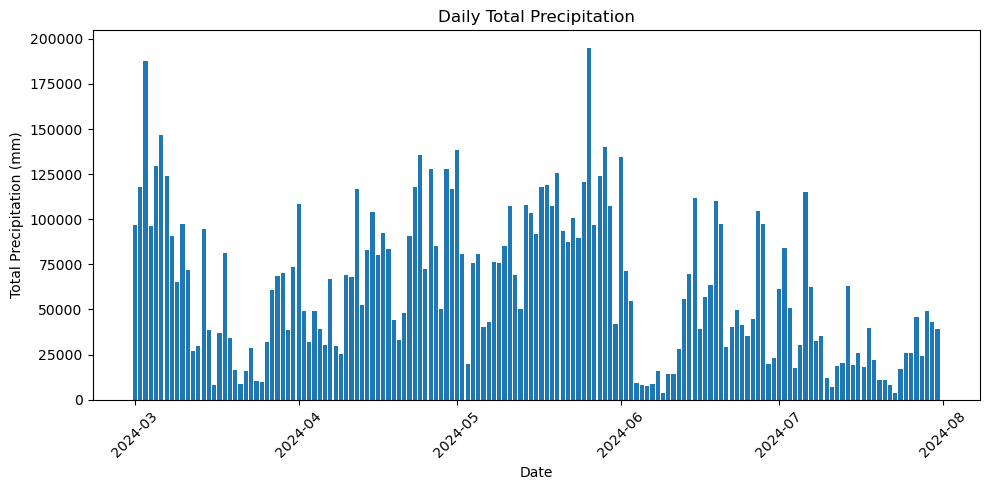

In [4]:
precip_df['date'] = pd.to_datetime(precip_df['date'])

daily_precip = (
    precip_df
    .groupby('date')['h_precip_mm']
    .sum()
    .reset_index()
)

plt.figure(figsize=(10,5))
plt.bar(daily_precip['date'], daily_precip['h_precip_mm'])
plt.xlabel('Date')
plt.ylabel('Total Precipitation (mm)')
plt.title('Daily Total Precipitation')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

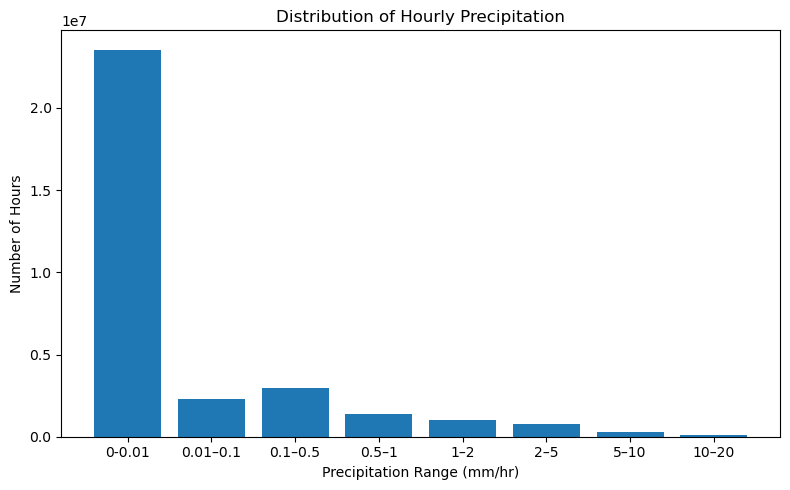

In [5]:
bins = [0,0.01, 0.1, 0.5, 1, 2, 5, 10, 20]
labels = ["0-0.01","0.01–0.1", "0.1–0.5", "0.5–1", "1–2", "2–5", "5–10", "10–20"]

precip_df["precip_bin"] = pd.cut(precip_df["h_precip_mm"],bins=bins,labels=labels,include_lowest=True)
bin_counts = precip_df["precip_bin"].value_counts().sort_index()

plt.figure(figsize=(8,5))
plt.bar(bin_counts.index.astype(str), bin_counts.values)
plt.xlabel("Precipitation Range (mm/hr)")
plt.ylabel("Number of Hours")
plt.title("Distribution of Hourly Precipitation")
plt.tight_layout()
plt.show()


## 2.0 TEMPO NO2
Files with detected pulses and without detected pulses 

In [6]:
# without detected pulses
all_no2_file='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/TEMPO_03-07_0.1x0.1GCF_all_hours.parquet'
no2_df = pd.read_parquet(all_no2_file, engine = 'pyarrow')

# with detected pulses 
no2_pulse_file = '/global/scratch/users/toireasamarie/TEMPO/parquet_files/GCF_no2_pulses_mar-july_3SD_2hourpulse_all_hours.parquet'
no2_pulse_df = pd.read_parquet(no2_pulse_file, engine='pyarrow')


In [7]:
no2_df


,date,hour,grid_lat,grid_lon,no2_mean,no2_std,no2_count,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std
0,2024-03-01,13:00:00,40.45,-83.25,3.744564e+15,1.428575e+15,12.0,0.122274,0.016299,0.336118,0.033229
1,2024-03-01,13:00:00,40.65,-81.85,2.829442e+15,8.430903e+14,22.0,0.119550,0.013558,0.335343,0.028645
2,2024-03-01,13:00:00,40.75,-82.85,4.133712e+15,2.052076e+15,13.0,0.135072,0.009735,0.363189,0.019019
3,2024-03-01,13:00:00,40.75,-82.75,2.637729e+15,1.453134e+15,25.0,0.131475,0.009193,0.356843,0.018450
4,2024-03-01,13:00:00,40.85,-82.75,4.007841e+15,2.218755e+15,24.0,0.138606,0.005802,0.370245,0.011293
...,...,...,...,...,...,...,...,...,...,...,...
5724371,2024-07-31,23:00:00,48.95,-99.65,1.497605e+15,9.706057e+14,14.0,0.138172,0.003511,0.383246,0.006432
5724372,2024-07-31,23:00:00,48.95,-99.15,9.474444e+14,7.457188e+14,19.0,0.139982,0.004388,0.384077,0.008831
5724373,2024-07-31,23:00:00,48.95,-98.85,1.819391e+15,6.468804e+14,15.0,0.144994,0.003071,0.392794,0.005961
5724374,2024-07-31,23:00:00,48.95,-98.75,1.899229e+15,4.420642e+14,25.0,0.142798,0.003860,0.388441,0.007575


In [8]:
no2_pulse_df

,date,hour,grid_lat,grid_lon,no2_mean,no2_std,no2_count,eff_cloud_fraction_mean,eff_cloud_fraction_std,amf_cloud_fraction_mean,amf_cloud_fraction_std,datetime,rolling_mean,rolling_std,pulse_threshold,above_3sd,prev_above,run_id,run_len,pulse_start
0,2024-03-01,15:00:00,36.05,-102.75,3.022860e+14,3.301698e+14,19.0,0.108975,0.008799,0.324750,0.017736,2024-03-01 15:00:00,NaN,NaN,NaN,False,False,1,90,False
1,2024-03-01,16:00:00,36.05,-102.75,4.568050e+14,3.856744e+14,20.0,0.080657,0.011436,0.252933,0.028406,2024-03-01 16:00:00,NaN,NaN,NaN,False,False,1,90,False
2,2024-03-01,17:00:00,36.05,-102.75,7.709887e+14,4.445936e+14,16.0,0.097015,0.015735,0.285615,0.035888,2024-03-01 17:00:00,NaN,NaN,NaN,False,False,1,90,False
3,2024-03-01,18:00:00,36.05,-102.75,4.733538e+14,3.418573e+14,20.0,0.069535,0.009845,0.231663,0.026811,2024-03-01 18:00:00,NaN,NaN,NaN,False,False,1,90,False
4,2024-03-01,19:00:00,36.05,-102.75,4.118467e+14,2.245340e+14,25.0,0.071411,0.008747,0.258869,0.023557,2024-03-01 19:00:00,NaN,NaN,NaN,False,False,1,90,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5724371,2024-07-30,15:00:00,48.95,-96.85,1.421450e+15,6.373422e+14,25.0,0.108949,0.001004,0.367346,0.002260,2024-07-30 15:00:00,NaN,NaN,NaN,False,False,9,43,False
5724372,2024-07-30,16:00:00,48.95,-96.85,1.048654e+15,5.388893e+14,25.0,0.092088,0.001035,0.323363,0.002772,2024-07-30 16:00:00,NaN,NaN,NaN,False,False,9,43,False
5724373,2024-07-30,17:00:00,48.95,-96.85,1.069067e+15,6.916846e+14,25.0,0.083836,0.000603,0.299821,0.001403,2024-07-30 17:00:00,NaN,NaN,NaN,False,False,9,43,False
5724374,2024-07-30,18:00:00,48.95,-96.85,9.332602e+14,4.532317e+14,25.0,0.108127,0.003257,0.371655,0.007352,2024-07-30 18:00:00,NaN,NaN,NaN,False,False,9,43,False


## 3.0 SMAP soil moisture 

In [9]:
smap_file ='/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/hourly_SMAP_03-07_0.1x0.1GCF.parquet'
smap_df = pd.read_parquet(smap_file, engine='pyarrow')
smap_df

,grid_lat,grid_lon,datetime,sm_surface,surface_temp,soil_temp_layer1,LAI,catchment_model_porosity,WFPS_c
0,36.05,-102.75,2024-02-29 22:00:00,NaN,NaN,NaN,NaN,NaN,NaN
1,36.05,-102.75,2024-02-29 23:00:00,0.113800,206.544754,204.246826,0.217461,0.303329,0.272184
2,36.05,-102.75,2024-03-01 00:00:00,0.113779,205.071732,204.240280,0.217711,0.303329,0.272134
3,36.05,-102.75,2024-03-01 01:00:00,0.113758,203.598724,204.233734,0.217961,0.303329,0.272084
4,36.05,-102.75,2024-03-01 02:00:00,0.113927,202.462418,203.997009,0.218211,0.303329,0.272486
...,...,...,...,...,...,...,...,...,...
34454767,48.95,-96.85,2024-07-31 19:00:00,0.072760,303.053467,298.235016,2.061263,0.400238,0.180363
34454768,48.95,-96.85,2024-07-31 20:00:00,0.072827,303.288666,298.772583,2.060860,0.400238,0.180547
34454769,48.95,-96.85,2024-07-31 21:00:00,0.072936,302.871277,299.129700,2.060457,0.400238,0.180834
34454770,48.95,-96.85,2024-07-31 22:00:00,0.073044,302.453888,299.486816,2.060053,0.400238,0.181121


## 4.0 Soil property data 

In [10]:
soil_props_file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/gridded_and_crop_filtered/soil_props_GCF.parquet'
soil_props_df = pd.read_parquet(soil_props_file, engine='pyarrow')
soil_props_df

,lat,lon,clay_percent,sand_percent,silt_percent,ksat,ph,soil_om_kg_m2,bulk_density,water_storage,...,pct_loam,pct_loamy_sand,pct_sand,pct_sandy_clay,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam
0,36.05,-102.65,17.036133,60.306217,22.657648,34.805645,7.506711,12.591521,1.529121,31.685999,...,27.272727,11.363636,0.0,0.0,6.060606,52.272727,0.0,0.000000,0.000000,0.000000
1,36.05,-102.15,29.947153,31.321022,38.731827,5.843044,7.349794,15.737164,1.497493,32.546562,...,22.916667,0.000000,0.0,0.0,0.694444,2.083333,0.0,0.000000,0.000000,27.083333
2,36.05,-101.95,32.300686,26.289616,41.409698,4.220728,7.324866,16.307981,1.484729,32.150986,...,6.944444,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,0.000000,43.750000
3,36.05,-91.15,17.243277,19.190384,63.566341,10.817478,5.641991,14.445125,1.438062,27.105488,...,4.545455,0.000000,0.0,0.0,0.000000,0.757576,0.0,86.363636,0.757576,7.575758
4,36.05,-90.95,28.162994,15.419770,56.417236,5.464124,5.997059,15.390757,1.401834,31.334503,...,3.030303,0.000000,0.0,0.0,0.000000,1.515152,0.0,46.212121,22.727273,26.515152
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3685,48.95,-97.95,23.840923,42.251835,33.902782,31.748346,7.439616,32.149502,1.427611,25.557028,...,15.909091,0.000000,0.0,0.0,1.515152,44.696970,0.0,6.060606,21.969697,3.787879
3686,48.95,-97.65,39.103363,10.376049,50.520588,3.539116,7.349593,43.052414,1.350748,31.006426,...,0.694444,0.000000,0.0,0.0,0.000000,0.000000,0.0,9.722222,51.388889,27.083333
3687,48.95,-97.45,44.942150,6.498482,48.559368,2.302964,7.304867,41.085045,1.341060,27.027557,...,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,3.787879,83.333333,12.878788
3688,48.95,-97.15,38.919182,7.280471,53.800346,5.508421,7.532484,40.113480,1.365370,33.844719,...,0.000000,0.000000,0.0,0.0,0.000000,0.000000,0.0,0.000000,36.111111,59.027778


## 5.0 State Data 

In [11]:
states = gpd.read_file("/global/scratch/users/toireasamarie/US_State_Shapefile/tl_2024_us_state.shp")

ERROR 1: PROJ: proj_create_from_database: Open of /global/home/users/toireasamarie/.conda/envs/regrid_env2/share/proj failed


In [12]:
states

,REGION,DIVISION,STATEFP,STATENS,GEOID,GEOIDFQ,STUSPS,NAME,LSAD,MTFCC,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,3,5,54,01779805,54,0400000US54,WV,West Virginia,00,G4000,A,62266513826,488918898,+38.6472854,-080.6183274,"POLYGON ((-77.75438 39.33346, -77.75422 39.333..."
1,3,5,12,00294478,12,0400000US12,FL,Florida,00,G4000,A,138965379385,45968913048,+28.3989775,-082.5143005,"MULTIPOLYGON (((-83.10874 24.62949, -83.10711 ..."
2,2,3,17,01779784,17,0400000US17,IL,Illinois,00,G4000,A,143778206717,6216848695,+40.1028754,-089.1526108,"POLYGON ((-87.89243 38.28285, -87.89334 38.282..."
3,2,4,27,00662849,27,0400000US27,MN,Minnesota,00,G4000,A,206244791203,18937236061,+46.3159573,-094.1996043,"POLYGON ((-95.31991 48.99892, -95.31778 48.998..."
4,3,5,24,01714934,24,0400000US24,MD,Maryland,00,G4000,A,25151223822,6979843236,+38.9466584,-076.6744939,"POLYGON ((-75.756 39.24607, -75.75578 39.24334..."
5,1,1,44,01219835,44,0400000US44,RI,Rhode Island,00,G4000,A,2677768885,1323681453,+41.5964850,-071.5264901,"MULTIPOLYGON (((-71.67881 41.15891, -71.67626 ..."
6,4,8,16,01779783,16,0400000US16,ID,Idaho,00,G4000,A,214050504522,2390996667,+44.3484222,-114.5588538,"POLYGON ((-116.35844 49.00047, -116.34805 49.0..."
7,1,1,33,01779794,33,0400000US33,NH,New Hampshire,00,G4000,A,23190211616,1025871482,+43.6727945,-071.5841886,"POLYGON ((-70.83887 43.24449, -70.83886 43.244..."
8,3,5,37,01027616,37,0400000US37,NC,North Carolina,00,G4000,A,125935965771,13453455061,+35.5397100,-079.1308636,"POLYGON ((-77.89977 36.5446, -77.89942 36.5446..."
9,1,1,50,01779802,50,0400000US50,VT,Vermont,00,G4000,A,23872594714,1030642813,+44.0589536,-072.6710173,"POLYGON ((-72.04187 44.15665, -72.0418 44.1566..."
